In [12]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model
import matplotlib.pyplot as plt

In [17]:
df = pd.read_csv("celeba.csv")

print(df.shape)
print(df.head())

(202599, 41)
     image_id  5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
0  000001.jpg                -1                1           1               -1   
1  000002.jpg                -1               -1          -1                1   
2  000003.jpg                -1               -1          -1               -1   
3  000004.jpg                -1               -1           1               -1   
4  000005.jpg                -1                1           1               -1   

   Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  ...  Sideburns  Smiling  \
0    -1     -1        -1        -1          -1  ...         -1        1   
1    -1     -1        -1         1          -1  ...         -1        1   
2    -1     -1         1        -1          -1  ...         -1       -1   
3    -1     -1        -1        -1          -1  ...         -1       -1   
4    -1     -1         1        -1          -1  ...         -1       -1   

   Straight_Hair  Wavy_Hair  Wearing_Earrings  We

In [18]:
X = df.drop("image_id", axis=1)

print(X.shape)

(202599, 40)


In [19]:
X = (X + 1) / 2

In [20]:
X = X.astype("float32").values

In [21]:
input_layer = layers.Input(shape=(40,))

encoded = layers.Dense(16, activation="relu")(input_layer)
encoded = layers.Dense(8, activation="relu")(encoded)

decoded = layers.Dense(16, activation="relu")(encoded)
decoded = layers.Dense(40, activation="sigmoid")(decoded)

autoencoder = Model(input_layer, decoded)

In [22]:
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

In [23]:
autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 40)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 40)                  │             680 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,616 (6.31 KB)

 Trainable params: 1,616 (6.31 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = autoencoder.fit(
    X,
    X,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3268 - val_loss: 0.2072
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1747 - val_loss: 0.1584
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1534 - val_loss: 0.1502
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1477 - val_loss: 0.1456
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1440 - val_loss: 0.1425
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1415 - val_loss: 0.1403
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1394 - val_loss: 0.1381
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1376 - val_loss: 0.1365
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1359 - val_loss: 0.1349
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1339 - val_loss: 0.1324
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1319 - val_loss: 0.1304
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

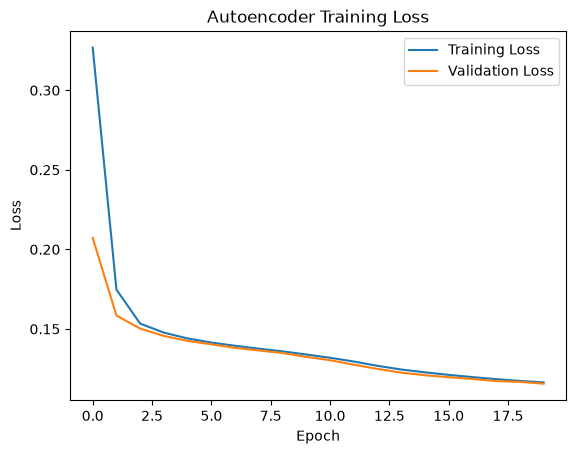

In [25]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")

plt.legend(["Training Loss", "Validation Loss"])
plt.show()

In [26]:
reconstructed = autoencoder.predict(X)

6332/6332 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step


In [27]:
print("Original:")
print(X[0])

print("\nReconstructed:")
print(reconstructed[0])

Original:
[0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 0. 0.
 1. 0. 0. 1. 0. 0. 0. 1. 1. 0. 1. 0. 1. 0. 0. 1.]

Reconstructed:
[1.04935185e-14 8.20523143e-01 9.75746930e-01 6.22002855e-02
 2.58884452e-08 7.93940574e-03 1.10028446e-01 1.09253905e-03
 3.42094069e-07 8.58172483e-04 1.89201441e-03 9.91923749e-01
 2.78695748e-04 3.95269666e-07 6.82950883e-07 2.24215478e-06
 2.88414016e-23 2.16007209e-07 9.99127865e-01 9.80326355e-01
 3.29522347e-12 9.96083677e-01 3.03132816e-16 2.12154552e-01
 1.00000000e+00 1.68966621e-01 1.76826045e-02 5.80674469e-01
 1.16092004e-01 2.35418290e-01 8.75430959e-34 9.97394979e-01
 9.98153329e-01 1.28239677e-07 9.18775260e-01 9.23617554e-05
 9.99744833e-01 1.53986990e-01 4.25848024e-10 9.99992251e-01]
